In [1]:
#data manipulation
import pandas as pd
import numpy as np

#data visualization
import matplotlib.pyplot as plt
import seaborn as sns

#preprocessing and modelling
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


#optional
import warnings
warnings.filterwarnings("ignore")

# Exploratory Data Analysis

In [2]:
#let's check the data
data = pd.read_csv('data/train-test.csv', parse_dates=['date'])
df = data.copy()
df.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [3]:
#let's check if features columns match with the training data

val_data =  pd.read_csv('data/validation.csv',parse_dates=['date'])

val_data.head()


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal
0,TE-000001,Baton Rouge,Mobile,30.50134,-92.65374,31.80442,-88.25195,331.4,Flatbed,19958.0,2025-11-01,0.90402,1.86388
1,TE-000002,Savannah,Los Angeles,33.60973,-82.29994,28.56624,-116.70249,2406.2,Reefer,34114.0,2025-11-01,0.92851,1.86240
2,TE-000003,San Francisco,Raleigh,35.19670,-121.69849,35.37376,-77.47605,2846.6,Dry Van,33435.0,2025-11-01,0.88117,1.95480
3,TE-000004,Dayton,Los Angeles,39.87206,-85.62931,28.56624,-116.70249,2261.6,Dry Van,25392.0,2025-11-01,0.89156,2.14579
4,TE-000005,Memphis,San Antonio,35.56802,-89.52871,29.50969,-98.40059,800.4,Flatbed,NaN,2025-11-01,0.88308,2.22541


In [4]:
#dimension
df.shape

(48000, 14)

In [5]:
#general info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   load_id       48000 non-null  object        
 1   pickup        48000 non-null  object        
 2   delivery      48000 non-null  object        
 3   pickup_lat    48000 non-null  float64       
 4   pickup_lon    48000 non-null  float64       
 5   delivery_lat  48000 non-null  float64       
 6   delivery_lon  48000 non-null  float64       
 7   distance      48000 non-null  float64       
 8   equipment     48000 non-null  object        
 9   weight        47700 non-null  float64       
 10  date          48000 non-null  datetime64[ns]
 11  market_index  47626 non-null  float64       
 12  quote_signal  48000 non-null  float64       
 13  posted_rate   48000 non-null  float64       
dtypes: datetime64[ns](1), float64(9), object(4)
memory usage: 5.1+ MB


In [6]:
#null values?
df.isnull().sum()

load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          300
date              0
market_index    374
quote_signal      0
posted_rate       0
dtype: int64

In [7]:
#duplicates?
df.duplicated().sum()

0

In [8]:
#Summary statistics
df.describe()

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,date,market_index,quote_signal,posted_rate
count,48000.000000,48000.000000,48000.000000,48000.000000,48000.000000,47700.000000,48000,47626.000000,48000.000000,48000.000000
mean,35.647545,-90.928964,35.641175,-90.857310,1135.856654,31028.844004,2025-05-31 19:53:29.400000,1.083387,2.062468,2373.980682
min,28.357650,-121.698490,28.357650,-121.698490,70.000000,-47500.000000,2025-01-01 00:00:00,0.676390,0.692280,57.220000
25%,31.986910,-98.400590,31.986910,-98.400590,550.400000,25800.000000,2025-03-18 00:00:00,0.949670,1.891030,1251.555000
50%,35.294790,-88.089150,35.294790,-87.528710,953.300000,31436.500000,2025-05-31 00:00:00,1.055800,2.055750,2030.760000
75%,39.411040,-83.285060,39.411040,-83.285060,1645.525000,37018.000000,2025-08-15 00:00:00,1.219590,2.221685,3330.750000
max,44.302960,-69.500000,44.302960,-69.500000,3439.800000,47500.000000,2025-10-31 00:00:00,1.467780,3.610350,25533.000000
std,4.315285,13.482431,4.317199,13.476589,728.564416,9391.440620,NaN,0.168091,0.291391,1486.493245


In [9]:
#summary stat for categorical variables
df.describe(include=[object])

,load_id,pickup,delivery,equipment
count,48000,48000,48000,48000
unique,48000,64,64,3
top,TR-000001,Oklahoma City,Lexington,Dry Van
freq,1,1242,1197,27202


In [10]:
# weight has impossible values; let's Check how many there are
print((df['weight'] < 0).sum())
print(df.loc[df['weight'] < 0, 'weight'].describe())

292
count      292.000000
mean    -31724.195205
std       8262.536326
min     -47500.000000
25%     -37284.250000
50%     -31821.500000
75%     -25928.500000
max      -5000.000000
Name: weight, dtype: float64


In [11]:
#let's fix them
df['weight'] = df['weight'].abs()

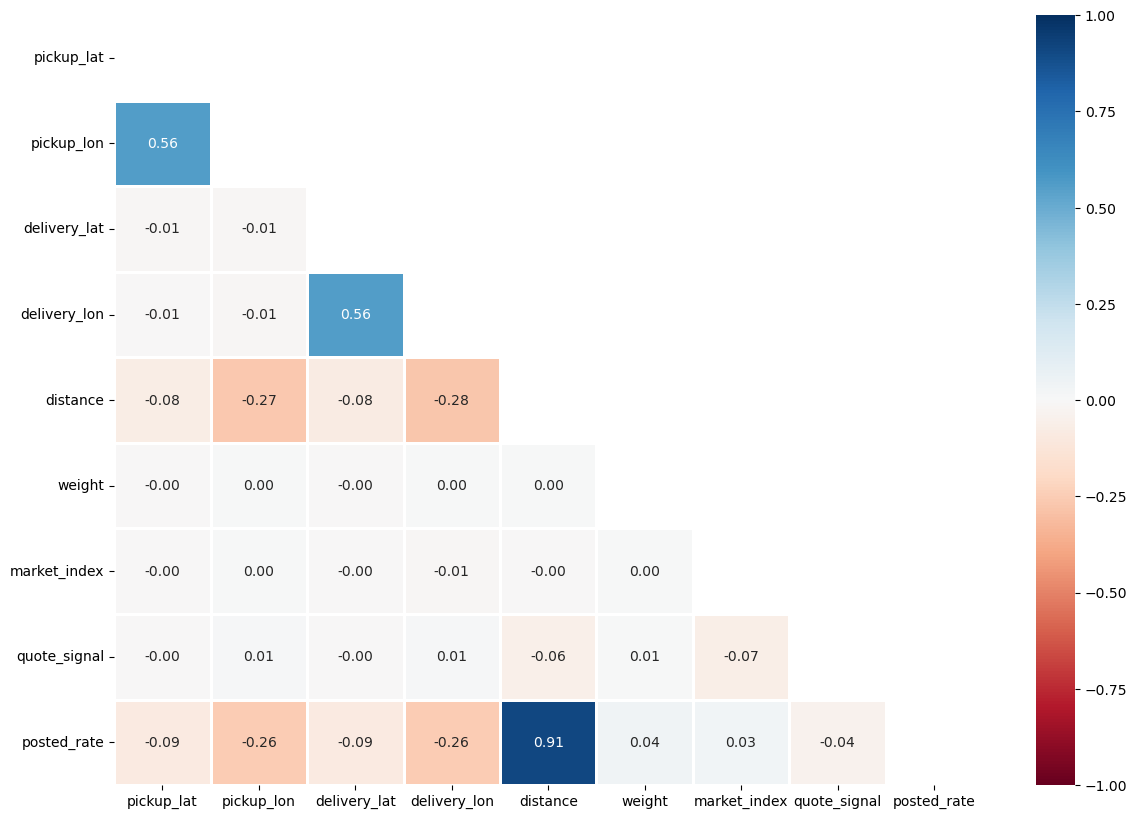

In [12]:
#bivariate analysis
corr = df.corr(numeric_only=True)

plt.figure(figsize=(14, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, center=0, cmap="RdBu", linewidths=1,
            annot=True, fmt=".2f", vmin=-1, vmax=1)
plt.savefig('correlation.png')
plt.show()

In [13]:
cat_cols = ['equipment', 'pickup', 'delivery']

for col in cat_cols:
    print(f"\n{col}: {df[col].nunique()} unique values")
    print(df[col].value_counts().head(10))
    print((df[col].value_counts(normalize=True).head(10) * 100).round(1).astype(str) + '%')


equipment: 3 unique values
equipment
Dry Van    27202
Reefer     12045
Flatbed     8753
Name: count, dtype: int64
equipment
Dry Van    56.7%
Reefer     25.1%
Flatbed    18.2%
Name: proportion, dtype: object

pickup: 64 unique values
pickup
Oklahoma City    1242
Lexington        1209
Bakersfield      1193
Fort Wayne       1170
Hartford         1150
Richmond         1140
Nashville        1124
Phoenix          1121
Baton Rouge      1115
Mobile           1094
Name: count, dtype: int64
pickup
Oklahoma City    2.6%
Lexington        2.5%
Bakersfield      2.5%
Fort Wayne       2.4%
Hartford         2.4%
Richmond         2.4%
Nashville        2.3%
Phoenix          2.3%
Baton Rouge      2.3%
Mobile           2.3%
Name: proportion, dtype: object

delivery: 64 unique values
delivery
Lexington        1197
Fort Wayne       1176
Baton Rouge      1167
Bakersfield      1156
Hartford         1143
Oklahoma City    1140
Richmond         1109
Atlanta          1096
Phoenix          1090
Mobile           10

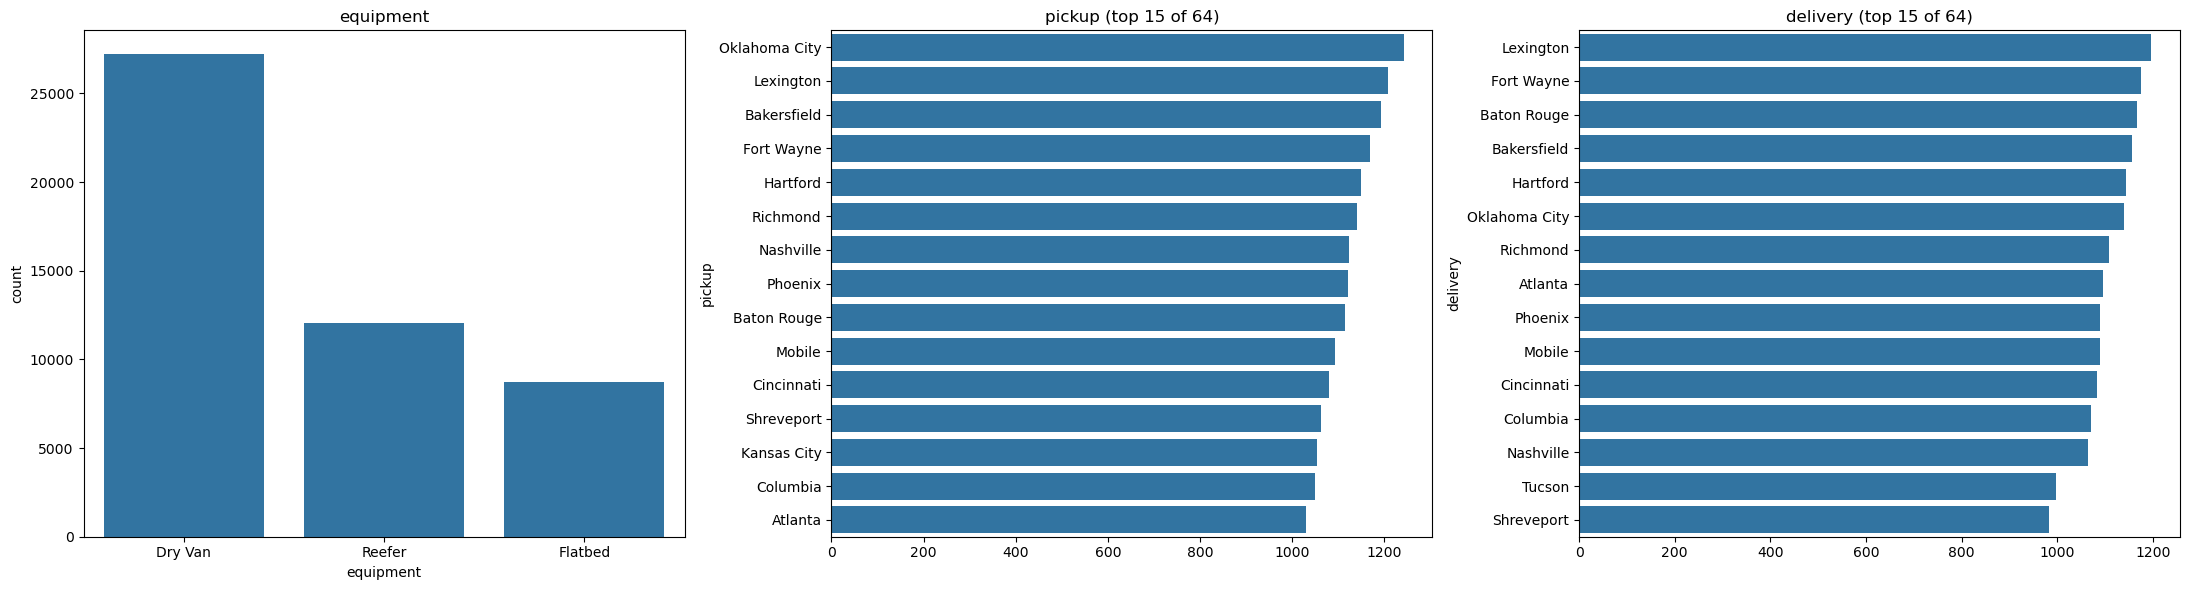

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

sns.countplot(data=df, x='equipment', order=df['equipment'].value_counts().index, ax=axes[0])
axes[0].set_title('equipment')

for ax, col in zip(axes[1:], ['pickup', 'delivery']):
    top = df[col].value_counts().head(15)
    sns.barplot(x=top.values, y=top.index, ax=ax)
    ax.set_title(f'{col} (top 15 of {df[col].nunique()})')

plt.tight_layout()
plt.show()

In [15]:
#weight and market_index are unrelated to every numeric column let's impute nans by the median
df['weight'] = df['weight'].fillna(df['weight'].median())
df['market_index'] = df['market_index'].fillna(df['market_index'].median())

In [16]:
#Since distance explains most of the target, the leftover variation is in how much is charged per mile
df['rate_per_mile'] = df['posted_rate'] / df['distance']
print(df['rate_per_mile'].describe())

# what explains the rate per mile?
print(df[['rate_per_mile', 'quote_signal', 'market_index', 'distance', 'weight']].corr()['rate_per_mile'])
print(df.groupby('equipment')['rate_per_mile'].median())
print(df.groupby(df['date'].dt.month)['rate_per_mile'].median())

count    48000.000000
mean         2.215347
std          0.583887
min          0.333709
25%          1.986974
50%          2.145348
75%          2.342696
max         14.125294
Name: rate_per_mile, dtype: float64
rate_per_mile    1.000000
quote_signal     0.049342
market_index     0.083360
distance        -0.334601
weight           0.092676
Name: rate_per_mile, dtype: float64
equipment
Dry Van    2.046203
Flatbed    2.219683
Reefer     2.311540
Name: rate_per_mile, dtype: float64
date
1     2.029158
2     2.061143
3     2.139279
4     2.146699
5     2.190194
6     2.247885
7     2.187422
8     2.120525
9     2.159622
10    2.163828
Name: rate_per_mile, dtype: float64


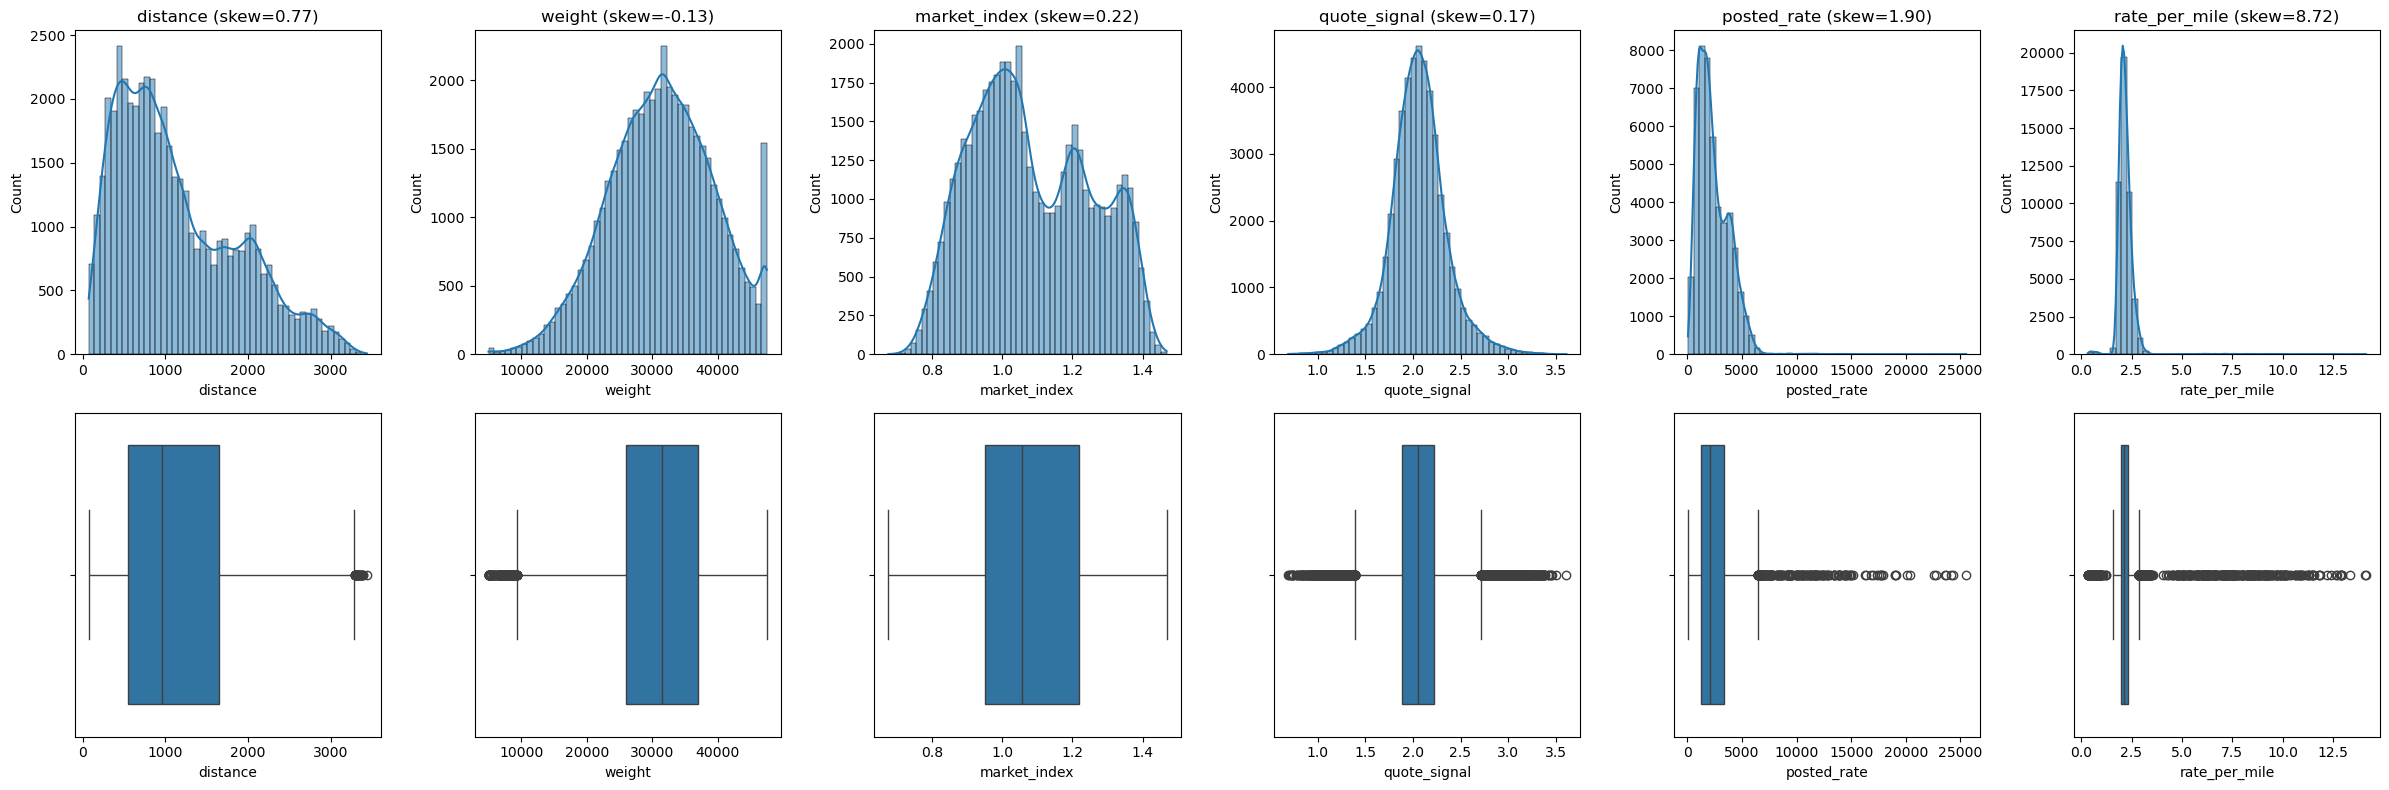

In [17]:
#distributions
num_cols = ['distance', 'weight', 'market_index', 'quote_signal', 'posted_rate', 'rate_per_mile']

fig, axes = plt.subplots(2, 6, figsize=(24, 8))
for i, col in enumerate(num_cols):
    sns.histplot(df[col].dropna(), bins=50, kde=True, ax=axes[0, i])
    axes[0, i].set_title(f"{col} (skew={df[col].skew():.2f})")
    sns.boxplot(x=df[col], ax=axes[1, i])
plt.tight_layout()
plt.savefig('distributions.png')
plt.show()

In [18]:

df['rpm_group'] = pd.cut(df['rate_per_mile'], [0, 1.5, 3.5, np.inf], labels=['low', 'normal', 'high'])

print(df['rpm_group'].value_counts())
print(df.groupby('rpm_group', observed=True)[['distance', 'quote_signal', 'market_index', 'weight']].median())
print(pd.crosstab(df['rpm_group'], df['equipment'], normalize='index').round(3))
print(df.groupby('rpm_group', observed=True)['date'].agg(['min', 'max']))

rpm_group
normal    47321
high        342
low         337
Name: count, dtype: int64
           distance  quote_signal  market_index   weight
rpm_group                                               
low           836.3      2.049260      1.052180  30145.0
normal        954.1      2.055860      1.055800  31496.0
high          926.8      2.032585      1.048125  31602.0
equipment  Dry Van  Flatbed  Reefer
rpm_group                          
low          0.507    0.190   0.303
normal       0.567    0.182   0.251
high         0.576    0.184   0.240
                 min        max
rpm_group                      
low       2025-01-01 2025-10-31
normal    2025-01-01 2025-10-31
high      2025-01-03 2025-10-31


In [19]:
norm_med = df.loc[df['rpm_group']=='normal','rate_per_mile'].median()
print((df['rate_per_mile'] / norm_med).groupby(df['rpm_group'], observed=True).describe())

             count      mean       std       min       25%       50%  \
rpm_group                                                              
low          337.0  0.296137  0.084976  0.155552  0.221749  0.285459   
normal     47321.0  1.019243  0.127099  0.734698  0.927268  1.000000   
high         342.0  3.612473  0.970572  1.639747  2.864975  3.491655   

                75%       max  
rpm_group                      
low        0.355664  0.584142  
normal     1.090367  1.620347  
high       4.246800  6.584246  


In [20]:
norm_med = df.loc[df['rpm_group'] == 'normal', 'rate_per_mile'].median()
ratio = df['rate_per_mile'] / norm_med
df['anomaly'] = (ratio < 0.65) | (ratio > 1.8)
print(df['anomaly'].sum())

677


In [21]:
import scipy.stats as st

n = df[~df['anomaly']].copy()
n['month'] = n['date'].dt.month
n['dir'] = np.where(n['delivery_lon'] > n['pickup_lon'], 'eastbound', 'westbound')
y = 'rate_per_mile'

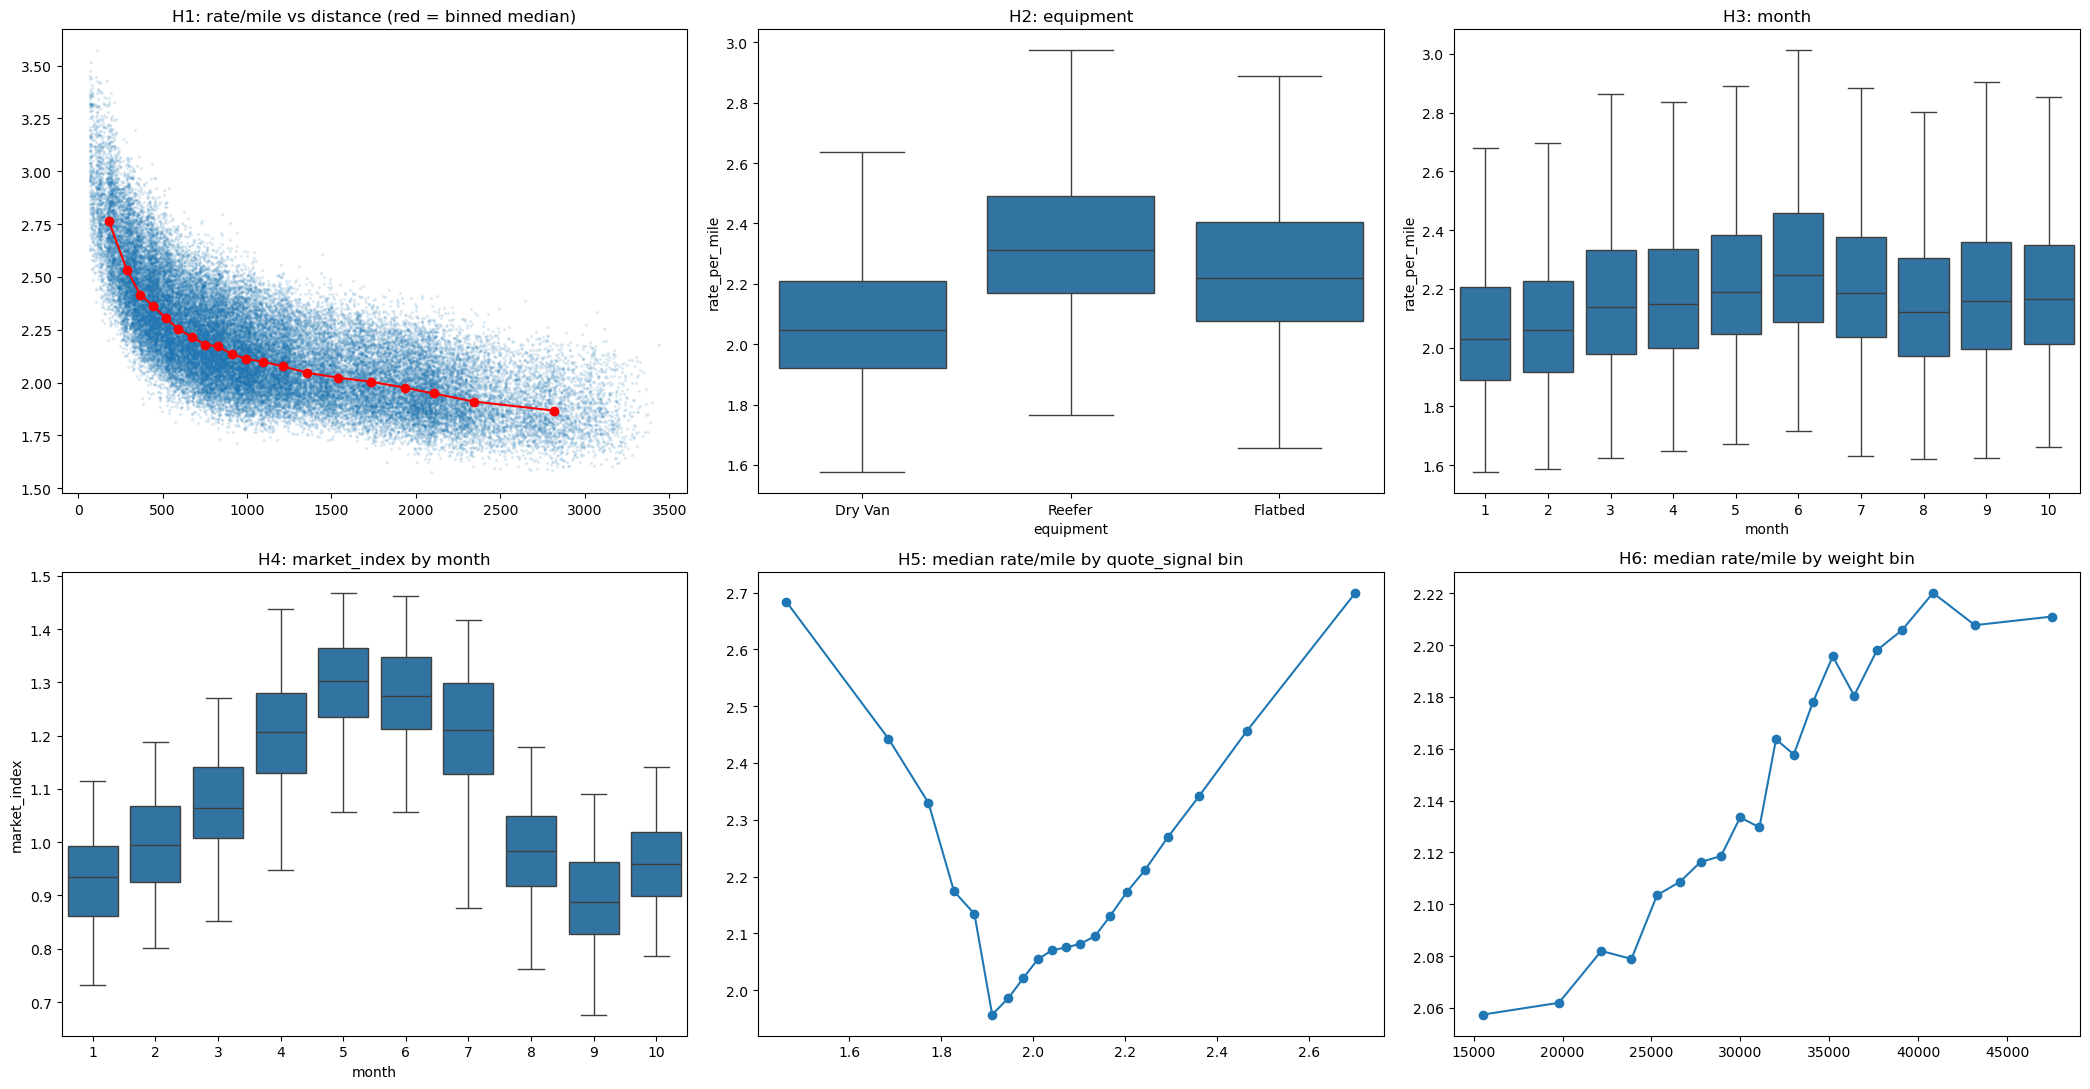

In [22]:
# ---------- PLOTS ----------
fig, ax = plt.subplots(2, 3, figsize=(21, 11))

# H1: distance
n['db'] = pd.qcut(n['distance'], 20)
g = n.groupby('db', observed=True).agg(d=('distance', 'median'), r=(y, 'median'))
ax[0, 0].scatter(n['distance'], n[y], s=2, alpha=0.1)
ax[0, 0].plot(g['d'], g['r'], 'r-o'); ax[0, 0].set_title('H1: rate/mile vs distance (red = binned median)')

# H2: equipment
sns.boxplot(data=n, x='equipment', y=y, showfliers=False, ax=ax[0, 1]); ax[0, 1].set_title('H2: equipment')

# H3: month
sns.boxplot(data=n, x='month', y=y, showfliers=False, ax=ax[0, 2]); ax[0, 2].set_title('H3: month')

# H4: market_index by month
sns.boxplot(data=n, x='month', y='market_index', ax=ax[1, 0]); ax[1, 0].set_title('H4: market_index by month')

# H5: quote_signal
n['qb'] = pd.qcut(n['quote_signal'], 20)
g = n.groupby('qb', observed=True).agg(q=('quote_signal', 'median'), r=(y, 'median'))
ax[1, 1].plot(g['q'], g['r'], 'o-'); ax[1, 1].set_title('H5: median rate/mile by quote_signal bin')

# H6: weight
n['wb'] = pd.qcut(n['weight'], 20, duplicates='drop')
g = n.groupby('wb', observed=True).agg(w=('weight', 'median'), r=(y, 'median'))
ax[1, 2].plot(g['w'], g['r'], 'o-'); ax[1, 2].set_title('H6: median rate/mile by weight bin')

plt.tight_layout(); plt.show()

In [23]:
# ---------- STATISTICAL TESTS ----------
from itertools import combinations

ALPHA = 0.05
y = 'rate_per_mile'
results = []

def size(v, kind):
    v = abs(v)
    cuts = (0.01, 0.06, 0.14) if kind == 'eps2' else (0.1, 0.3, 0.5)
    return ['negligible', 'small', 'moderate', 'large'][sum(v >= c for c in cuts)]

# ---- Spearman (numeric vs numeric)
for c in ['distance', 'quote_signal', 'weight', 'market_index']:
    rho, p = st.spearmanr(n[c], n[y])
    results.append(dict(test=f'Spearman {c} vs {y}',
        H0=f'no monotonic link between {c} and {y}',
        p=p, es=rho, kind='r',
        direction=f"higher {c} -> {'higher' if rho > 0 else 'lower'} {y}"))

# ---- Kruskal-Wallis (numeric vs 3+ groups)
for col, target in [('equipment', y), ('month', y), ('month', 'market_index')]:
    groups = [g[target].values for _, g in n.groupby(col)]
    H, p = st.kruskal(*groups)
    eps2 = (H - len(groups) + 1) / (len(n) - len(groups))
    top = n.groupby(col)[target].median().idxmax()
    results.append(dict(test=f'Kruskal {target} by {col}',
        H0=f'{target} has the same distribution in every {col}',
        p=p, es=eps2, kind='eps2', direction=f'highest median in {col} = {top}'))

# ---- Mann-Whitney (2 groups)
def mw(a, b, name, la, lb):
    U, p = st.mannwhitneyu(a, b)
    r = 2 * U / (len(a) * len(b)) - 1          # > 0 means group a tends to be higher
    results.append(dict(test=name, H0=f'{la} and {lb} have the same {y} distribution',
        p=p, es=r, kind='r', direction=f"{la if r > 0 else lb} tends to be higher"))

mw(n.loc[n['dir']=='eastbound', y], n.loc[n['dir']=='westbound', y],
   'Mann-Whitney eastbound vs westbound', 'eastbound', 'westbound')

for e1, e2 in combinations(n['equipment'].unique(), 2):
    mw(n.loc[n['equipment']==e1, y], n.loc[n['equipment']==e2, y],
       f'Mann-Whitney {e1} vs {e2}', e1, e2)

# ---- Decisions with Bonferroni over ALL tests
k = len(results)
alpha_adj = ALPHA / k
for r in results:
    mag = size(r['es'], r['kind'])
    r['effect'] = f"{r['es']:.3f} ({mag})"
    if r['p'] >= alpha_adj:
        r['decision'] = 'FAIL TO REJECT H0'
        r['conclusion'] = f"No evidence against: {r['H0']}."
    elif mag == 'negligible':
        r['decision'] = 'REJECT H0 (negligible effect)'
        r['conclusion'] = 'Statistically detectable but too small to matter. Low priority as a feature.'
    else:
        r['decision'] = f'REJECT H0 ({mag} effect)'
        r['conclusion'] = f"Supports H1: {r['direction']}. Worth keeping as a feature."

out = pd.DataFrame(results)[['test', 'p', 'effect', 'decision', 'conclusion']]
out['p'] = out['p'].map(lambda v: f'{v:.2e}')
print(f'{k} tests, Bonferroni alpha = {alpha_adj:.4f}\n')
for _, r in out.iterrows():
    print(f"{r['test']}\n   p={r['p']} | effect={r['effect']}\n   -> {r['decision']}: {r['conclusion']}\n")

11 tests, Bonferroni alpha = 0.0045

Spearman distance vs rate_per_mile
   p=0.00e+00 | effect=-0.757 (large)
   -> REJECT H0 (large effect): Supports H1: higher distance -> lower rate_per_mile. Worth keeping as a feature.

Spearman quote_signal vs rate_per_mile
   p=8.96e-93 | effect=0.094 (negligible)
   -> REJECT H0 (negligible effect): Statistically detectable but too small to matter. Low priority as a feature.

Spearman weight vs rate_per_mile
   p=0.00e+00 | effect=0.203 (small)
   -> REJECT H0 (small effect): Supports H1: higher weight -> higher rate_per_mile. Worth keeping as a feature.

Spearman market_index vs rate_per_mile
   p=0.00e+00 | effect=0.185 (small)
   -> REJECT H0 (small effect): Supports H1: higher market_index -> higher rate_per_mile. Worth keeping as a feature.

Kruskal rate_per_mile by equipment
   p=0.00e+00 | effect=0.209 (large)
   -> REJECT H0 (large effect): Supports H1: highest median in equipment = Reefer. Worth keeping as a feature.

Kruskal rate_per_m

### Key Findings from EDA

- The development dataset contains 48,000 rows and 14 columns.
- There are no duplicate rows in the dataset.
- Missing values are limited and manageable:
- weight has 300 missing values and market_index has 374 missing values
- The weight column contained 292 impossible negative values, which were corrected by taking the absolute value.
- Categorical variables are well structured:
    - equipment has 3 categories: Dry Van, Reefer, and Flatbed
    - pickup and delivery each have 64 unique cities
    - The dataset is dominated by Dry Van loads, which make up about 56.7% of the records.
- posted_rate is right-skewed, with a wide range of values and some high-cost outliers.
- distance is the strongest pricing driver in the dataset.
- rate_per_mile is a useful engineered feature that gives a clearer view of pricing than posted_rate alone.
- Equipment type has a meaningful effect on pricing:
    - Reefer loads generally have the highest rate per mile
    - Flatbed is intermediate
    - Dry Van has the lowest
- weight and market_index show smaller but still useful relationships with pricing.
- quote_signal has only a very weak practical relationship with rate per mile.
- Month has a small seasonal effect on pricing.
- Eastbound vs westbound direction does not show a meaningful difference in rate per mile.
- A small number of records were flagged as anomalous based on unusually low or high rate_per_mile values.



# Data Preprocessing & Modelling

In [24]:
pre_df = data.copy()
#sort by date
pre_df = pre_df.sort_values('date').reset_index(drop=True)

In [25]:
#Split Chronogically
cutoff_date = '2025-10-01'

train_df = pre_df[pre_df['date'] < cutoff_date].copy()
valid_df = pre_df[pre_df['date'] >= cutoff_date].copy()

In [26]:
#applying preprocessing rules
def basic_preprocess(df_in):
    df = df_in.copy()
    df['weight'] = df['weight'].abs()
    df['dayofweek'] = df['date'].dt.dayofweek
    df['dayofmonth'] = df['date'].dt.day
    df['is_month_start'] = df['date'].dt.is_month_start.astype(int)
    df['is_month_end'] = df['date'].dt.is_month_end.astype(int)
    return df

train_df = basic_preprocess(train_df)
valid_df = basic_preprocess(valid_df)


In [27]:
#impute missing values using training data only
weight_median = train_df['weight'].median()
market_median = train_df['market_index'].median()

for d in [train_df, valid_df]:
    d['weight'] = d['weight'].fillna(weight_median)
    d['market_index'] = d['market_index'].fillna(market_median)


In [28]:
# separate target and features
X_train = train_df.drop(columns=['posted_rate', 'load_id', 'date'])
y_train = train_df['posted_rate']

X_valid = valid_df.drop(columns=['posted_rate', 'load_id', 'date'])
y_valid = valid_df['posted_rate']

In [29]:
# only use training data to define anomaly rules
train_rpm = train_df['posted_rate'] / train_df['distance']
rpm_median = train_rpm.median()

train_df['rpm_ratio'] = train_rpm / rpm_median
train_df['anomaly'] = (train_df['rpm_ratio'] < 0.65) | (train_df['rpm_ratio'] > 1.8)

print("Training anomalies:", train_df['anomaly'].sum())

train_df = train_df[~train_df['anomaly']].copy()


Training anomalies: 597


In [30]:
#confirm the columns
print(X_train.columns.tolist())
print(X_train.dtypes)

['pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'market_index', 'quote_signal', 'dayofweek', 'dayofmonth', 'is_month_start', 'is_month_end']
pickup             object
delivery           object
pickup_lat        float64
pickup_lon        float64
delivery_lat      float64
delivery_lon      float64
distance          float64
equipment          object
weight            float64
market_index      float64
quote_signal      float64
dayofweek           int32
dayofmonth          int32
is_month_start      int32
is_month_end        int32
dtype: object


In [31]:
#defining categorical and numerical columns
cat_cols = ["equipment", "pickup", "delivery"]
num_cols = [c for c in X_train.columns if c not in cat_cols]

print("Categorical columns:", cat_cols)
print("Numeric columns:", num_cols)

Categorical columns: ['equipment', 'pickup', 'delivery']
Numeric columns: ['pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'weight', 'market_index', 'quote_signal', 'dayofweek', 'dayofmonth', 'is_month_start', 'is_month_end']


In [32]:
#build the preprocessing pipeline
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_cols),
        ("cat", categorical_transformer, cat_cols)
    ]
)



In [33]:
#baseline model: Ridge
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", Ridge(alpha=1.0))
])
model.fit(X_train,y_train)
y_pred = model.predict(X_valid)

In [34]:
#evaluate performance
mae = mean_absolute_error(y_valid, y_pred)
rmse = np.sqrt(mean_squared_error(y_valid, y_pred))
r2 = r2_score(y_valid, y_pred)

print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2:   {r2:.4f}")


MAE:  154.2629
RMSE: 656.7448
R2:   0.8154


In [35]:
#comparison model: RandomForestRegressor
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        max_depth=None,
        min_samples_leaf=2
    ))
])

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_valid)

rf_mae = mean_absolute_error(y_valid, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_valid, rf_pred))
rf_r2 = r2_score(y_valid, rf_pred)

print(f"Random Forest MAE:  {rf_mae:.4f}")
print(f"Random Forest RMSE: {rf_rmse:.4f}")
print(f"Random Forest R2:   {rf_r2:.4f}")


Random Forest MAE:  154.4317
Random Forest RMSE: 673.0097
Random Forest R2:   0.8061


In [36]:
#comparison Model 2
from sklearn.ensemble import HistGradientBoostingRegressor

hgbr_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", HistGradientBoostingRegressor(
        learning_rate=0.05,
        max_depth=6,
        max_iter=300,
        min_samples_leaf=20,
        l2_regularization=0.0,
        random_state=42
    ))
])

hgbr_model.fit(X_train, y_train)
hgbr_pred = hgbr_model.predict(X_valid)

hgbr_mae = mean_absolute_error(y_valid, hgbr_pred)
hgbr_rmse = np.sqrt(mean_squared_error(y_valid, hgbr_pred))
hgbr_r2 = r2_score(y_valid, hgbr_pred)

print(f"HistGradientBoosting MAE:  {hgbr_mae:.4f}")
print(f"HistGradientBoosting RMSE: {hgbr_rmse:.4f}")
print(f"HistGradientBoosting R2:   {hgbr_r2:.4f}")


HistGradientBoosting MAE:  127.7168
HistGradientBoosting RMSE: 654.0721
HistGradientBoosting R2:   0.8169


In [37]:
comparison = pd.DataFrame({
    "model": ["Ridge", "Random Forest",'Hist Gradient Boosting' ],
    "MAE": [mae, rf_mae,hgbr_mae],
    "RMSE": [rmse, rf_rmse,hgbr_rmse],
    "R2": [r2, rf_r2,hgbr_r2]
})

comparison


,model,MAE,RMSE,R2
0,Ridge,154.262882,656.744791,0.815401
1,Random Forest,154.431707,673.009662,0.806144
2,Hist Gradient Boosting,127.716833,654.072057,0.816900


In [38]:
# Final refit on all labeled development data

# Rebuild the full labeled dataset
full_df = pd.read_csv("data/train-test.csv", parse_dates=["date"]).copy()

# Apply the same preprocessing
full_df = basic_preprocess(full_df)

# Impute missing values using the full labeled data
weight_median_full = full_df["weight"].median()
market_median_full = full_df["market_index"].median()
quote_median_full = full_df["quote_signal"].median()

full_df["weight"] = full_df["weight"].fillna(weight_median_full)
full_df["market_index"] = full_df["market_index"].fillna(market_median_full)
full_df["quote_signal"] = full_df["quote_signal"].fillna(quote_median_full)

# Apply the same anomaly filter idea on the full labeled data
full_rpm = full_df["posted_rate"] / full_df["distance"]
full_rpm_median = full_rpm.median()
full_df["rpm_ratio"] = full_rpm / full_rpm_median
full_df["anomaly"] = (full_df["rpm_ratio"] < 0.65) | (full_df["rpm_ratio"] > 1.8)

print("Full labeled rows before filter:", len(full_df))
print("Full labeled anomalies flagged:", full_df["anomaly"].sum())

full_df = full_df[~full_df["anomaly"]].copy()

print("Full labeled rows after filter:", len(full_df))

# Final feature split
X_full = full_df.drop(columns=["posted_rate", "load_id", "date", "rpm_ratio", "anomaly"])
y_full = full_df["posted_rate"]

# Final preprocessing setup
cat_cols = ["equipment", "pickup", "delivery"]
num_cols = [c for c in X_full.columns if c not in cat_cols]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

final_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_cols),
        ("cat", categorical_transformer, cat_cols)
    ]
)

# Final model
final_model = Pipeline(steps=[
    ("preprocessor", final_preprocessor),
    ("regressor", HistGradientBoostingRegressor(
        learning_rate=0.05,
        max_depth=6,
        max_iter=300,
        min_samples_leaf=20,
        l2_regularization=0.0,
        random_state=42
    ))
])

# Fit final model on all labeled development data
final_model.fit(X_full, y_full)

print("Final model refit complete.")

Full labeled rows before filter: 48000
Full labeled anomalies flagged: 677
Full labeled rows after filter: 47323
Final model refit complete.


In [39]:
print("Final model ready:", final_model is not None)

Final model ready: True


In [40]:
#prediction on trainng set
y_train_pred = final_model.predict(X_train)

# predictions on validation set
y_valid_pred = final_model.predict(X_valid)

def evaluate(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"{name} MAE:  {mae:.4f}")
    print(f"{name} RMSE: {rmse:.4f}")
    print(f"{name} R2:   {r2:.4f}")
    print()

evaluate(y_train, y_train_pred, "Train")
evaluate(y_valid, y_valid_pred, "Valid")

Train MAE:  86.3730
Train RMSE: 583.0683
Train R2:   0.8451

Valid MAE:  106.3375
Valid RMSE: 649.4086
Valid R2:   0.8195



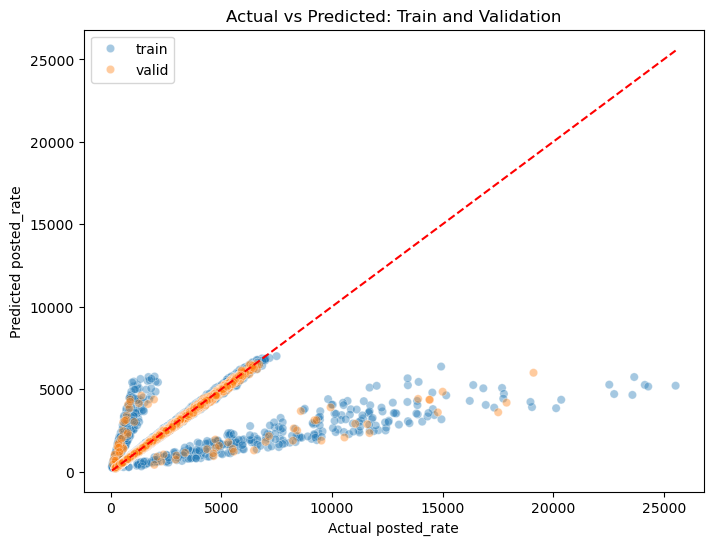

In [41]:
#plot predicted vs actual plot

train_results = pd.DataFrame({
    "actual": y_train,
    "predicted": y_train_pred,
    "split": "train"
})

valid_results = pd.DataFrame({
    "actual": y_valid,
    "predicted": y_valid_pred,
    "split": "valid"
})

results = pd.concat([train_results, valid_results], ignore_index=True)

plt.figure(figsize=(8, 6))
sns.scatterplot(data=results, x="actual", y="predicted", hue="split", alpha=0.4)
plt.plot([results["actual"].min(), results["actual"].max()],
         [results["actual"].min(), results["actual"].max()],
         color="red", linestyle="--")
plt.xlabel("Actual posted_rate")
plt.ylabel("Predicted posted_rate")
plt.title("Actual vs Predicted: Train and Validation")
plt.legend()
plt.savefig('Actual_vs_Predicted.png')
plt.show()

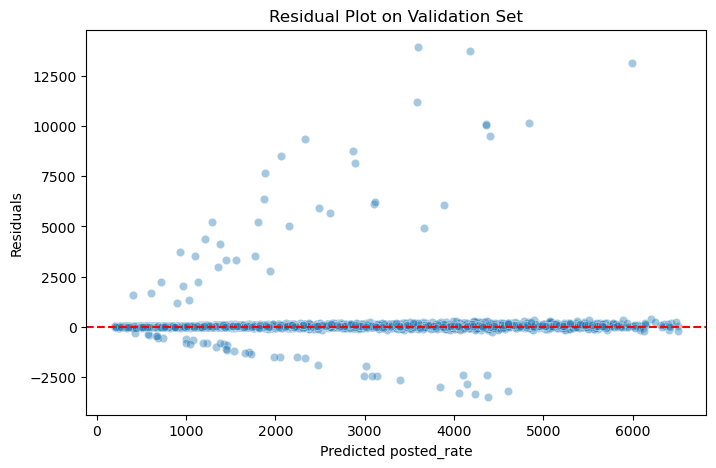

In [42]:
#residual plot
valid_residuals = y_valid - y_valid_pred

plt.figure(figsize=(8, 5))
sns.scatterplot(x=y_valid_pred, y=valid_residuals, alpha=0.4)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted posted_rate")
plt.ylabel("Residuals")
plt.title("Residual Plot on Validation Set")
plt.savefig('Residual_plot.png')
plt.show()


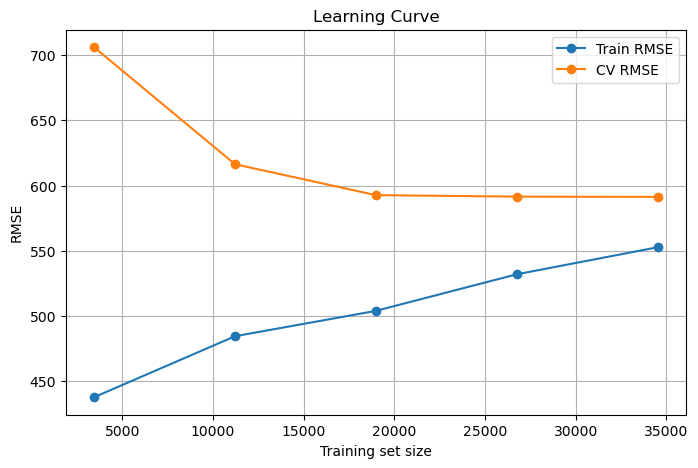

In [43]:
#learning curve
from sklearn.model_selection import learning_curve

train_sizes, train_scores, valid_scores = learning_curve(
    final_model,
    X_train,
    y_train,
    cv=5,
    scoring="neg_root_mean_squared_error",
    train_sizes=np.linspace(0.1, 1.0, 5),
    n_jobs=-1
)

train_rmse = -train_scores.mean(axis=1)
valid_rmse = -valid_scores.mean(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_rmse, marker="o", label="Train RMSE")
plt.plot(train_sizes, valid_rmse, marker="o", label="CV RMSE")
plt.xlabel("Training set size")
plt.ylabel("RMSE")
plt.title("Learning Curve")
plt.legend()
plt.grid(True)
plt.savefig('Learning_curve.png')
plt.show()


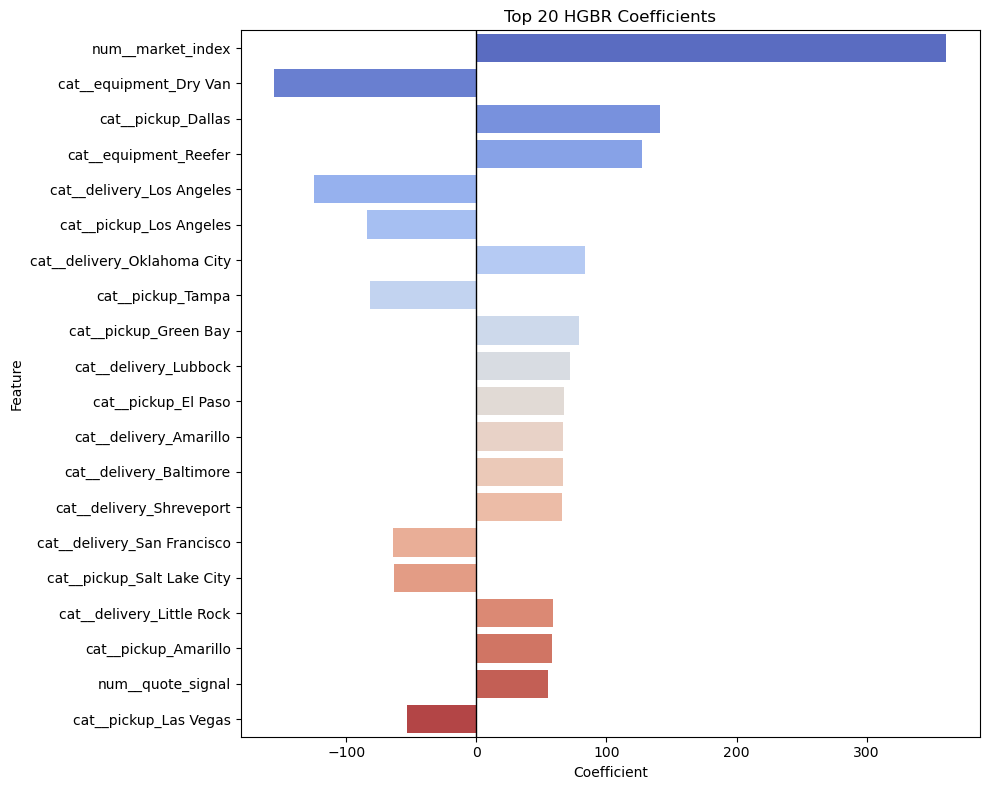

In [44]:
#feature importance
# Get feature names after preprocessing
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

# Get Ridge coefficients
coefs = model.named_steps["regressor"].coef_

# Build a table
coef_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefs,
    "abs_coefficient": abs(coefs)
}).sort_values("abs_coefficient", ascending=False)

# Top 20 most influential features
top20 = coef_df.head(20)

plt.figure(figsize=(10, 8))
sns.barplot(data=top20, x="coefficient", y="feature", palette="coolwarm")
plt.axvline(0, color="black", linewidth=1)
plt.title("Top 20 HGBR Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig('Explanability.png')
plt.show()

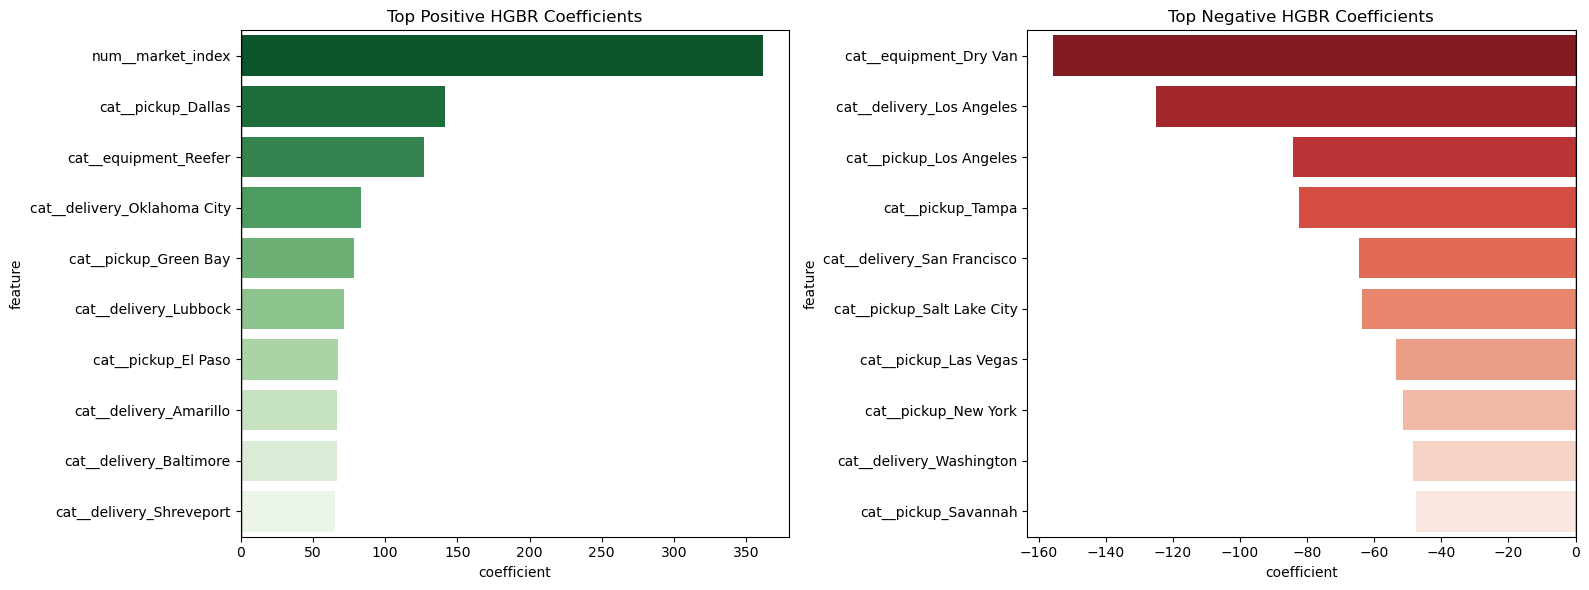

In [45]:
top_positive = coef_df.sort_values("coefficient", ascending=False).head(10)
top_negative = coef_df.sort_values("coefficient", ascending=True).head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=top_positive, x="coefficient", y="feature", ax=axes[0], palette="Greens_r")
axes[0].set_title("Top Positive HGBR Coefficients")
axes[0].axvline(0, color="black", linewidth=1)

sns.barplot(data=top_negative, x="coefficient", y="feature", ax=axes[1], palette="Reds_r")
axes[1].set_title("Top Negative HGBR Coefficients")
axes[1].axvline(0, color="black", linewidth=1)

plt.tight_layout()
plt.show()


### Preprocessing and Modelling: Summary and Key Findings

- A chronological split was used to create the training and validation sets:
    - records before 2025-10-01 were used for training
    - records on or after 2025-10-01 were used for validation
    - This split avoided leakage and matched the forecasting nature of the task.

- Time-based features were tested during modelling, but month and quarter were removed from the final pipeline because they did not improve validation performance and could extrapolate poorly into unseen months.

- Numeric and categorical variables were preprocessed separately:
    - numeric features were imputed using the median
    - categorical features were imputed using the most frequent category
    - the categorical variables equipment, pickup, and delivery were one-hot encoded

- A training anomaly filter was applied using rate-per-mile:
    - unusually low or high rate-per-mile rows were removed from the training split only
    - this reduced noisy extreme observations and improved validation MAE

- Several models were compared on the same validation split:
    - Ridge Regression
    - Random Forest Regression
    - HistGradientBoostingRegressor

- Validation performance:
    - Ridge Regression: MAE 146.9187, RMSE 654.2295, R² 0.8168
    - Random Forest Regression: MAE 154.6093, RMSE 673.4272, R² 0.8059
    - HistGradientBoostingRegressor: MAE 127.7168, RMSE 654.0721, R² 0.8169

- HistGradientBoostingRegressor was selected as the final model because it achieved the best overall validation performance.

- Residual plots and learning curves were used to inspect model behavior and confirm that the model was learning meaningful structure without obvious leakage.

- The final model will be refit on all labeled development data before producing the submission predictions for validation.csv.


In [46]:
#load val and the template
val = pd.read_csv("data/validation.csv", parse_dates=["date"])
template = pd.read_csv("data/validation-predictions-template.csv")

In [47]:
#val info
val.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   load_id       12000 non-null  object        
 1   pickup        12000 non-null  object        
 2   delivery      12000 non-null  object        
 3   pickup_lat    12000 non-null  float64       
 4   pickup_lon    12000 non-null  float64       
 5   delivery_lat  12000 non-null  float64       
 6   delivery_lon  12000 non-null  float64       
 7   distance      12000 non-null  float64       
 8   equipment     12000 non-null  object        
 9   weight        11835 non-null  float64       
 10  date          12000 non-null  datetime64[ns]
 11  market_index  11751 non-null  float64       
 12  quote_signal  12000 non-null  float64       
dtypes: datetime64[ns](1), float64(8), object(4)
memory usage: 1.2+ MB


In [48]:
# same preprocessing as training/validation split
val = basic_preprocess(val)

# use training medians, not validation medians
val["weight"] = val["weight"].fillna(weight_median)
val["market_index"] = val["market_index"].fillna(market_median)

# same model input columns as training
X_final = val.drop(columns=["load_id", "date"])

# make sure column order matches training
X_final = X_final[X_train.columns]

# predict
preds = final_model.predict(X_final)

# keep predictions positive for scorer
preds = np.maximum(preds, 1e-6)

# fill template and save
submission = template.copy()
submission["predicted_rate"] = preds
submission.to_csv("validation_predictions.csv", index=False)

submission.head()

,load_id,predicted_rate
0,TE-000001,807.660669
1,TE-000002,4896.638910
2,TE-000003,5211.798293
3,TE-000004,4066.457791
4,TE-000005,1794.707482


In [49]:
#load december_chart_inputs.csv 
dec = pd.read_csv("data/december-chart-inputs.csv", parse_dates=["date"])
dec_out = dec.copy()

In [50]:
dec_out.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   pickup          31 non-null     object        
 1   delivery        31 non-null     object        
 2   distance        31 non-null     int64         
 3   equipment       31 non-null     object        
 4   weight          31 non-null     int64         
 5   date            31 non-null     datetime64[ns]
 6   predicted_rate  0 non-null      float64       
dtypes: datetime64[ns](1), float64(1), int64(2), object(3)
memory usage: 1.8+ KB


In [51]:
# Rebuild the extra feature columns the trained model expects
dec_model = dec_out.copy()

# map pickup/delivery to coordinates from training data
pickup_map = train_df.drop_duplicates("pickup").set_index("pickup")[["pickup_lat", "pickup_lon"]]
delivery_map = train_df.drop_duplicates("delivery").set_index("delivery")[["delivery_lat", "delivery_lon"]]

dec_model = dec_model.merge(pickup_map, left_on="pickup", right_index=True, how="left")
dec_model = dec_model.merge(delivery_map, left_on="delivery", right_index=True, how="left")

# add the missing numeric training features
dec_model["market_index"] = market_median
dec_model["quote_signal"] = train_df["quote_signal"].median()

# apply the same preprocessing as training
dec_model = basic_preprocess(dec_model)

# fill any missing numeric columns using training medians
for col in X_train.columns:
    if col in dec_model.columns and pd.api.types.is_numeric_dtype(X_train[col]):
        if dec_model[col].isna().any():
            dec_model[col] = dec_model[col].fillna(X_train[col].median())

# make sure the feature columns match training exactly
X_dec = dec_model[X_train.columns]

# predict
dec_pred = final_model.predict(X_dec)

# keep predictions positive for scorer
dec_pred = np.maximum(dec_pred, 1e-6)

# put predictions into the original december file structure
dec_out["predicted_rate"] = dec_pred

#save a NEW file, do not overwrite the source
dec_out.to_csv("data/december_chart_inputs_filled.csv", index=False)

dec_out.head()

,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,801.516073
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,801.488918
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,808.820003
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,807.018585
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,802.269767


In [52]:
import sys
print("Notebook Python:", sys.executable)

Notebook Python: C:\Users\HTS\anaconda3\envs\rate-model\python.exe


In [53]:
!{sys.executable} score.py --predictions validation_predictions.csv --december-predictions data/december_chart_inputs_filled.csv


Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: scorer_results\candidate_december.png
Final validation metrics are calculated by Spotter after submission.
